# Results
Run `bash scripts/finalize.sh` (or the individual scripts) first. Cells skip gracefully if a file is missing.

In [1]:
import pathlib, re, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
ROOT = pathlib.Path('..') if pathlib.Path('../benchmarks/results').exists() else pathlib.Path('.')
R = ROOT / 'benchmarks' / 'results'; L = ROOT / 'logs'
sys.path.insert(0, str(ROOT / 'scripts'))
from make_results_tables import LABELS, GROUPS, pretty
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

## 1. Baseline iteration counts (Poisson)

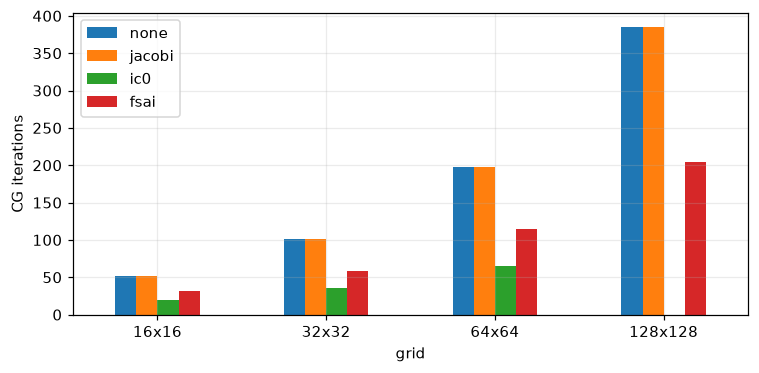

In [2]:
b = pd.read_csv(R/'day1_baselines.csv')
cols = [c for c in ['none','jacobi','ic0','fsai'] if c in b]
b.set_index('grid')[cols].plot.bar(figsize=(7,3.5), rot=0); plt.ylabel('CG iterations'); plt.tight_layout(); plt.show()

## 2. Training curves (validation CG iterations on Poisson 32², from `logs/`)
This matrix is in-distribution: it shows the model learns FSAI quality, not generalization.

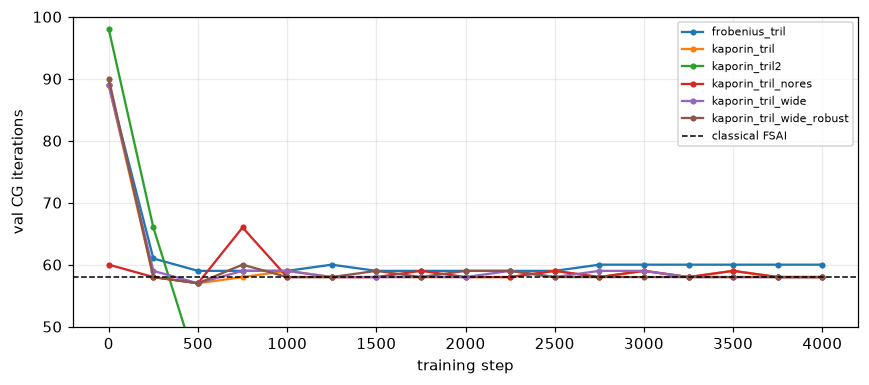

In [3]:
pat = re.compile(r"step\s+(\d+)\s+train\s+\S+\s+\S+\s+val CG iters \(32\^2\)\s+(\d+)")
fig, ax = plt.subplots(figsize=(8,3.6)); found = False
for f in sorted(L.glob('*.log')) if L.exists() else []:
    pts = [(int(m.group(1)), int(m.group(2))) for m in map(pat.search, f.read_text().splitlines()) if m]
    if pts:
        found = True; ax.plot(*zip(*pts), marker='.', label=f.stem)
tgt = re.search(r"FSAI\(tril\)=(\d+)", ''.join(f.read_text() for f in sorted(L.glob('*.log')))) if L.exists() else None
if tgt: ax.axhline(int(tgt.group(1)), color='k', ls='--', lw=1, label='classical FSAI')
ax.set_xlabel('training step'); ax.set_ylabel('val CG iterations'); ax.set_ylim(50, 100)
if found: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. GNN vs baselines (final weights)

In [4]:
f = R/'eval_all.csv'
e = pd.read_csv(f) if f.exists() else None
if e is not None:
    if 'converged' not in e: e['converged'] = True
    it = e.pivot_table(index='matrix', columns='method', values='iters', aggfunc='first')
    cv = e.pivot_table(index='matrix', columns='method', values='converged', aggfunc='first')
    order = [m for g in GROUPS for m in g[1] if m in it.index]
    meths = [m for m in ['none','jacobi','ic0','pyamg_amg','fsai_tril','fsai_tril2'] if m in it.columns] + sorted(m for m in it.columns if m.startswith('gnn_'))
    t = it.loc[order, meths].rename(index=LABELS, columns=pretty)
    display(t)
else:
    print('eval_all.csv not found - run scripts/evaluate_checkpoint.py')

method,none,jacobi,IC(0),AMG (pyamg),FSAI (tril),FSAI (tril²),GNN Frobenius tril,GNN Kaporin tril²,GNN Kaporin tril,GNN Kaporin tril (wide),"GNN Kaporin tril (wide, robust)"
matrix,,,,,,,,,,,
Poisson 16²,52.0,52.0,20.0,6.0,30.0,23.0,31.0,23.0,30.0,30.0,30.0
Poisson 32²,101.0,101.0,34.0,7.0,58.0,41.0,60.0,43.0,58.0,58.0,58.0
Poisson 64²,199.0,199.0,65.0,8.0,113.0,81.0,110.0,83.0,113.0,113.0,113.0
Poisson 128² (unseen size),379.0,379.0,NaN,8.0,201.0,153.0,206.0,158.0,201.0,202.0,202.0
Anisotropic 64² (ay=0.01),366.0,366.0,32.0,31.0,195.0,136.0,204.0,166.0,197.0,198.0,196.0
Random 2D family #0,150.0,150.0,50.0,7.0,81.0,61.0,82.0,63.0,81.0,81.0,81.0
Random 2D family #1,210.0,209.0,62.0,8.0,111.0,79.0,114.0,88.0,111.0,111.0,111.0
Random 2D family #2,198.0,198.0,65.0,8.0,113.0,80.0,116.0,83.0,113.0,114.0,113.0
3D Poisson 16³,64.0,64.0,23.0,6.0,36.0,27.0,38.0,32.0,37.0,36.0,36.0


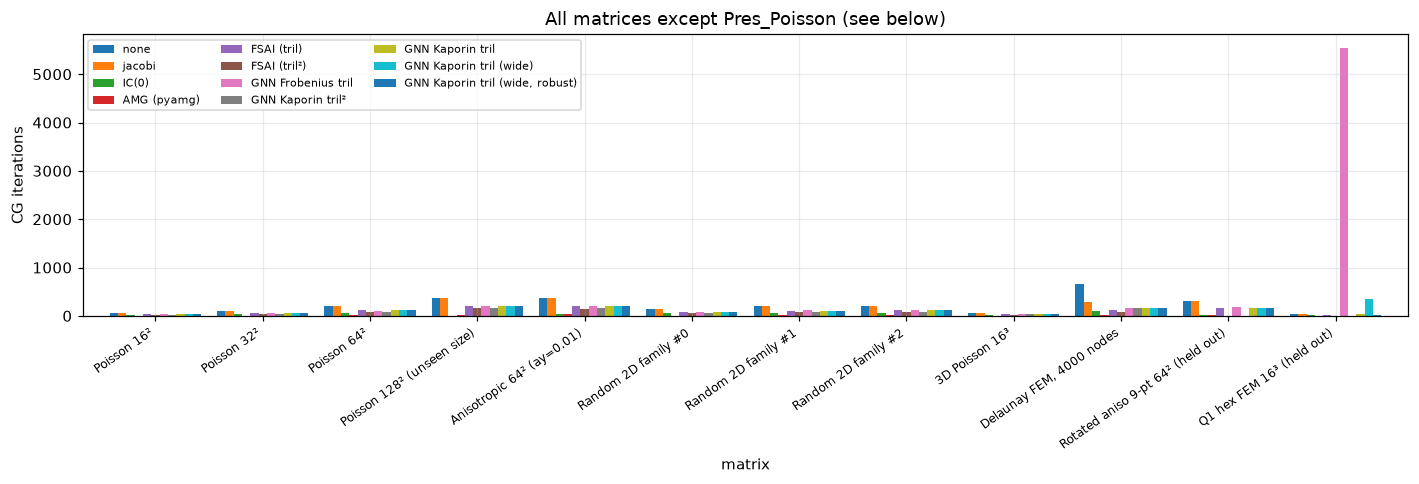

In [5]:
if e is not None:
    sub = [m for m in order if m != 'suitesparse']
    t2 = it.loc[sub, meths].rename(index=LABELS, columns=pretty)
    t2.plot.bar(figsize=(13,4.5), width=.85); plt.ylabel('CG iterations'); plt.xticks(rotation=35, ha='right', fontsize=8)
    plt.legend(fontsize=7, ncol=3); plt.title('All matrices except Pres_Poisson (see below)'); plt.tight_layout(); plt.show()

## 4. How far is each GNN from classical FSAI? (% more iterations; ✗ = no convergence)

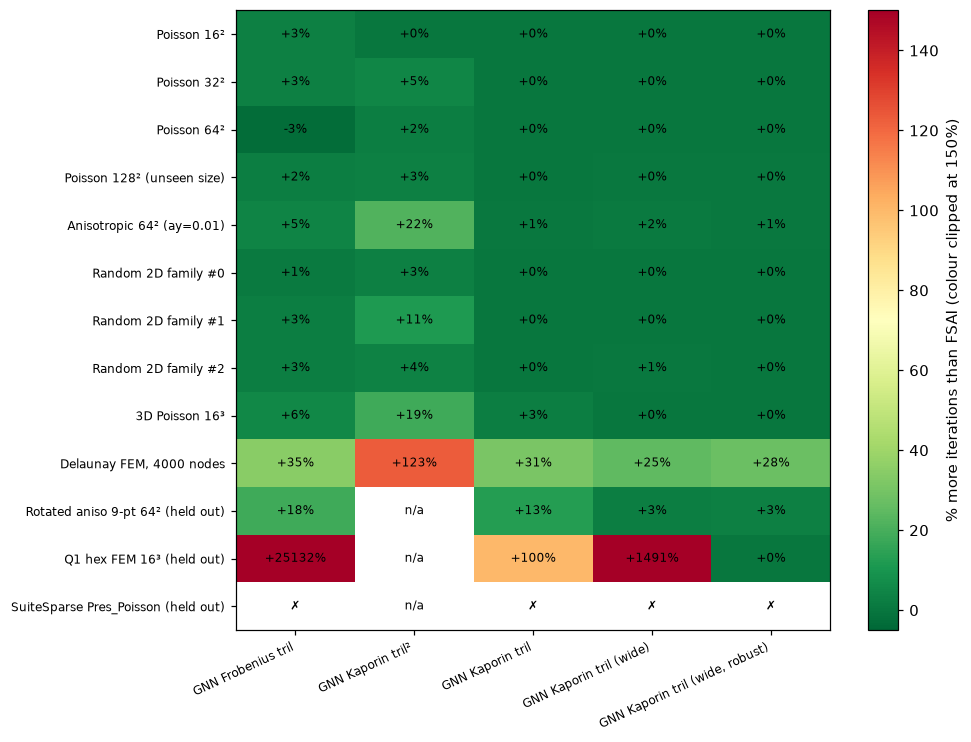

In [6]:
if e is not None:
    gn = [m for m in meths if m.startswith('gnn_')]
    gap = pd.DataFrame(index=order, columns=gn, dtype=float); note = pd.DataFrame('', index=order, columns=gn)
    for mat in order:
        for m in gn:
            ref = 'fsai_tril2' if 'tril2' in m else 'fsai_tril'
            v, fv = it.at[mat, m], it.at[mat, ref] if ref in it.columns else np.nan
            if pd.isna(v) or pd.isna(fv): note.at[mat, m] = 'n/a'; continue
            if not bool(cv.at[mat, m]): note.at[mat, m] = '✗'; continue
            gap.at[mat, m] = (v / fv - 1) * 100
    fig, ax = plt.subplots(figsize=(1.6 + 1.5*len(gn), 0.45*len(order) + 1))
    im = ax.imshow(np.clip(gap.values.astype(float), -5, 150), cmap='RdYlGn_r', aspect='auto', vmin=-5, vmax=150)
    for i, mat in enumerate(order):
        for j, m in enumerate(gn):
            txt = note.iat[i, j] or f"{gap.iat[i, j]:+.0f}%"
            ax.text(j, i, txt, ha='center', va='center', fontsize=8)
    ax.set_xticks(range(len(gn))); ax.set_xticklabels([pretty(m) for m in gn], rotation=25, ha='right', fontsize=8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([LABELS.get(m, m) for m in order], fontsize=8); ax.grid(False)
    plt.colorbar(im, label='% more iterations than FSAI (colour clipped at 150%)'); plt.tight_layout(); plt.show()

## 5. Held-out matrices: iterations relative to no preconditioner (below 1 = helps, above 1 = hurts)

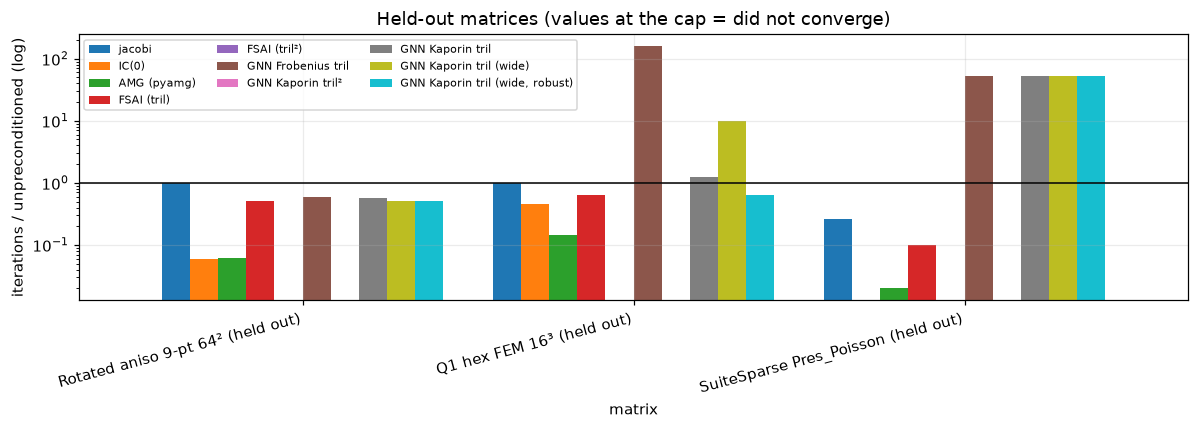

In [7]:
if e is not None:
    held = [m for m in ['heldout_rotaniso9_64','heldout_q1hex_16','suitesparse'] if m in it.index]
    show = [m for m in meths if m != 'none']
    rel = (it.loc[held, show].div(it.loc[held, 'none'], axis=0)).rename(index=LABELS, columns=pretty)
    ax = rel.plot.bar(figsize=(11,4), logy=True, width=.85); ax.axhline(1, color='k', lw=1)
    ax.set_ylabel('iterations / unpreconditioned (log)'); plt.xticks(rotation=15, ha='right'); plt.legend(fontsize=7, ncol=3)
    plt.title('Held-out matrices (values at the cap = did not converge)'); plt.tight_layout(); plt.show()

## 6. Residual history, Poisson 64²

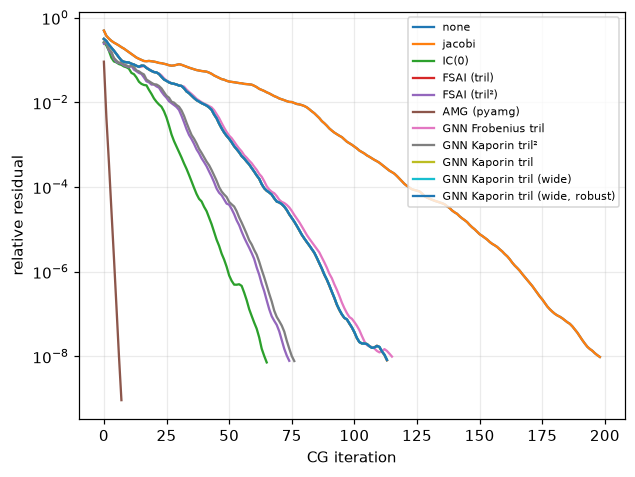

In [8]:
f = R/'eval_curves.npz'
if f.exists():
    c = np.load(f)
    for k in c.files: plt.semilogy(c[k], label=pretty(k))
    plt.xlabel('CG iteration'); plt.ylabel('relative residual'); plt.legend(fontsize=7); plt.show()
else:
    print('eval_curves.npz not found')

## 7. Does the loss predict iterations? (FSAI-family stand-in study, 32 matrices x 6 preconditioners)

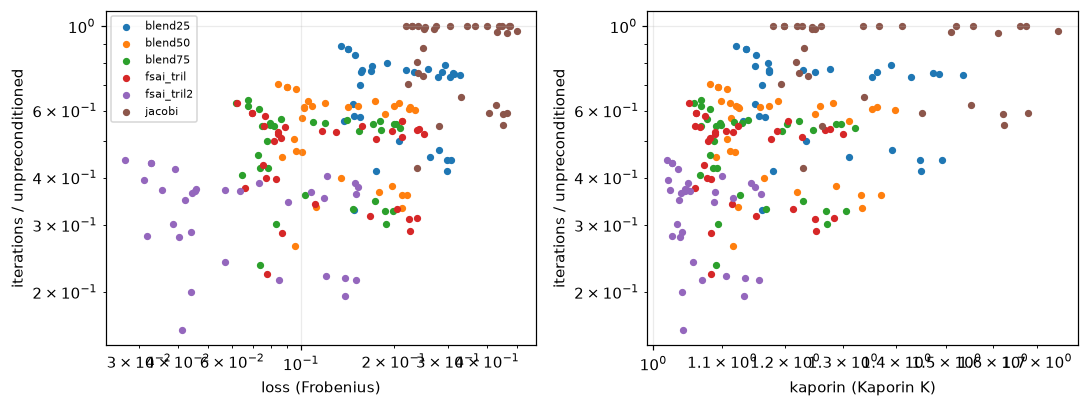

,pooled_R2,within_spearman_mean,within_spearman_min
loss,0.26695,0.916912,0.828571
kaporin,0.18562,0.998201,0.985611


In [9]:
d = pd.read_csv(R/'correlation_study.csv')
none = d[d.method=='none'].set_index('matrix').iters
d['rel_iters'] = d.apply(lambda r: r.iters/none[r.matrix], axis=1)
d = d[(d.method!='none')].dropna(subset=['loss','kaporin'])
fig, ax = plt.subplots(1,2,figsize=(10,3.8))
for a,col in zip(ax,['loss','kaporin']):
    for m,g in d.groupby('method'): a.scatter(g[col], g.rel_iters, s=14, label=m)
    a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel(col + (' (Frobenius)' if col=='loss' else ' (Kaporin K)')); a.set_ylabel('iterations / unpreconditioned')
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
display(pd.read_csv(R/'correlation_summary.csv', index_col=0))

## 8. Spectra

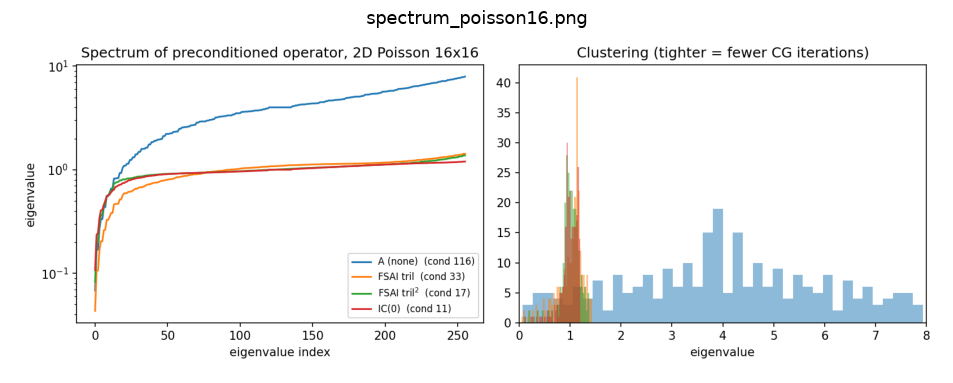

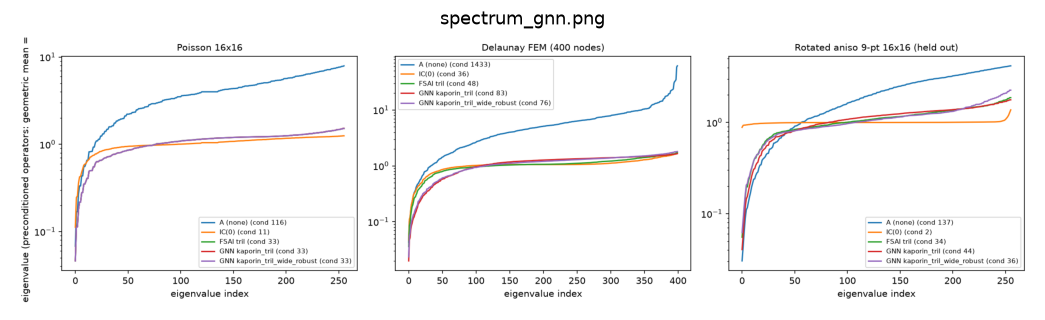

In [10]:
for name in ['spectrum_poisson16.png', 'spectrum_gnn.png']:
    p = R/name
    if p.exists():
        plt.figure(figsize=(12, 4)); plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(name); plt.show()
    else:
        print(name, 'not found')